# 04 · Reliability and failures
Questions 9–16. Customer-caused failures (insufficient funds, wrong PIN, limits) are kept apart from **operational** failures, which the bank and its partners own.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

,attempts,success_rate_pct,customer_failure_pct,operational_failure_pct,unknown_failure_pct,worst_operational_rank
channel,,,,,,
ATM,226442,97.46,1.94,0.56,0.03,6
Mobile App,872054,96.73,2.08,1.15,0.04,5
Internet Banking,233771,97.12,1.48,1.37,0.03,4
Wallet Link,127241,98.60,0.00,1.38,0.02,3
Agent,239453,95.97,1.42,2.56,0.05,2
USSD,323727,94.15,2.50,3.28,0.08,1


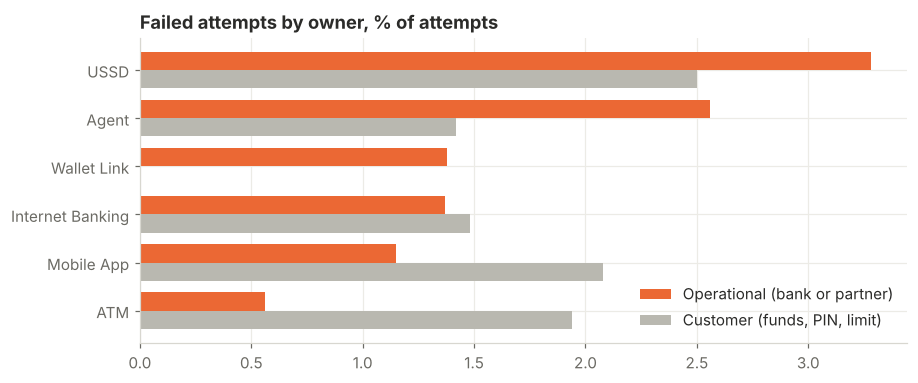

In [2]:
r = o('q09_success_rate_by_channel').set_index('channel').sort_values('operational_failure_pct')
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(r)); w = 0.38
ax.barh(y + w/2, r.operational_failure_pct, w, color=an.HIGHLIGHT, label='Operational (bank or partner)')
ax.barh(y - w/2, r.customer_failure_pct, w, color=an.CONTEXT, label='Customer (funds, PIN, limit)')
ax.set_yticks(y, r.index); ax.set_title("Failed attempts by owner, % of attempts"); ax.legend(loc='lower right')
an.save(fig, "failure_rates_by_channel"); r

**USSD is the least reliable channel** (3.3% of attempts fail for operational reasons), followed by agents (2.6%). The app and ATMs are the most reliable.

In [3]:
o('q10_failure_reasons_by_channel').query('channel in ["USSD", "Agent", "Mobile App"]')

,channel,failure_reason,failure_owner,failures,share_of_channel_failures_pct
6,Agent,Agent float unavailable,Operational,4842,50.20
7,Agent,Insufficient funds,Customer,1888,19.60
8,Agent,Incorrect PIN,Customer,1354,14.00
9,Agent,Timeout,Operational,926,9.60
10,Agent,System outage,Operational,361,3.70
11,Agent,Limit exceeded,Customer,151,1.60
12,Agent,Unknown,Unknown,127,1.30
19,Mobile App,Insufficient funds,Customer,11510,40.30
20,Mobile App,Incorrect PIN,Customer,5357,18.80
21,Mobile App,Timeout,Operational,4688,16.40


,hour,ussd_pct,mobile_app_pct,agent_pct,ussd_attempts
8,8,2.28,1.02,2.38,20395
12,12,2.33,1.00,2.59,18249
17,17,4.56,1.07,2.39,18441
18,18,5.31,1.18,2.30,23586
19,19,5.13,1.28,2.45,26129
20,20,5.22,1.56,2.20,23546
21,21,5.04,1.50,2.76,18482
23,23,2.46,1.12,NaN,7841


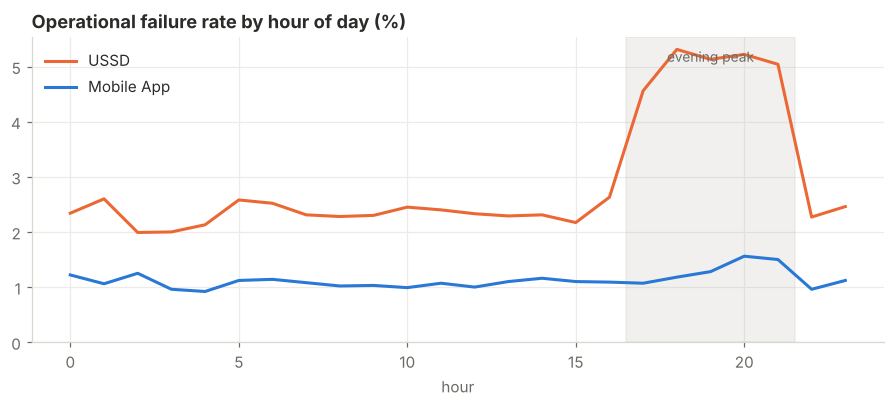

In [4]:
hr = o('q11_failure_by_hour')
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hr.hour, hr.ussd_pct, color=an.HIGHLIGHT, label='USSD'); ax.plot(hr.hour, hr.mobile_app_pct, color=an.PRIMARY, label='Mobile App')
ax.axvspan(16.5, 21.5, color=an.CONTEXT, alpha=0.2); ax.text(19, ax.get_ylim()[1]*0.92, 'evening peak', ha='center', color=an.INK_MUTED, fontsize=9)
ax.set_title("Operational failure rate by hour of day (%)"); ax.set_xlabel('hour'); ax.set_ylim(0); ax.legend()
an.save(fig, "ussd_failures_by_hour"); hr.loc[[8, 12, 17, 18, 19, 20, 21, 23]]

USSD operational failures more than double in the evening peak (17:00–21:00), when session capacity is under most pressure. The app stays flat through the day.

In [5]:
o('q12_agent_float_month_end')

,period,day_type,agent_withdrawal_attempts,float_failures,float_failure_pct
0,Payday window (25th-2nd),Weekday,33500,2077,6.20
1,Payday window (25th-2nd),Weekend,12568,788,6.27
2,Rest of month,Weekday,62726,630,1.00
3,Rest of month,Weekend,24051,1347,5.60


Agent cash withdrawals fail for lack of float about **6% of the time on payday days and at weekends**, against 1% on ordinary weekdays: agents run out of cash exactly when customers need it most.

In [6]:
o('q13_retry_and_recovery')

,failure_owner,failure_reason,failures,retried_within_30min_pct,recovered_pct,retries_on_other_channel_pct,not_recovered
0,Customer,NaN,37490,21.10,19.90,0.00,30040
1,Customer,Insufficient funds,23090,4.90,4.60,0.10,22036
2,Customer,Incorrect PIN,10954,59.90,56.90,0.00,4719
3,Customer,Limit exceeded,3446,4.90,4.70,0.00,3285
4,Operational,NaN,33023,52.80,49.10,20.00,16822
5,Operational,Timeout,10475,53.90,51.50,19.90,5080
6,Operational,Third-party unavailable,9138,54.00,51.80,23.20,4408
7,Operational,USSD session dropped,6788,53.50,50.00,29.20,3391
8,Operational,Agent float unavailable,4842,53.60,48.30,0.00,2503
9,Operational,System outage,1780,35.70,19.10,23.20,1440


About **half of operational failures are retried within 30 minutes, and about half are recovered** (the retry succeeds). Around 20–30% of retries after a timeout or a dropped USSD session happen on a different channel, usually the app. The other half are lost transactions. During outages, recovery falls to about 19%.

In [7]:
o('q14_incident_impact')

,incident_id,channel,start_ts,hours,severity,attempts,operational_failures,failure_rate_pct,normal_rate_same_hours_pct,unrecovered,fees_lost_kes
0,INC-001,Mobile App,2025-06-14 19:00:00,3.00,Minor,275,144,52.40,1.45,107,"1,980.00"
1,INC-002,USSD,2025-07-31 18:00:00,4.00,Major,234,146,62.40,5.18,116,"1,348.00"
2,INC-003,Agent,2025-08-29 10:00:00,6.00,Major,276,151,54.70,2.73,131,"5,880.00"
3,INC-004,Internet Banking,2025-09-15 09:00:00,2.00,Minor,38,20,52.60,1.39,18,"1,010.00"
4,INC-006,ATM,2025-11-30 07:00:00,8.00,Major,234,119,50.90,0.62,102,"3,366.00"
5,INC-007,USSD,2025-12-23 17:00:00,5.00,Major,201,117,58.20,5.05,91,990.00
6,INC-008,Wallet Link,2026-01-12 11:00:00,4.00,Major,39,16,41.00,1.33,14,0.00
7,INC-009,Mobile App,2026-03-13 18:00:00,3.00,Minor,486,303,62.30,1.34,245,"5,150.00"
8,INC-011,Agent,2026-06-30 09:00:00,7.00,Major,433,232,53.60,2.70,197,"10,740.00"
9,INC-012,Mobile App,2026-08-21 20:00:00,2.00,Minor,311,173,55.60,1.53,133,"3,140.00"


During logged incidents, the affected channel fails 41–62% of attempts, against under 1% to 5% normally at the same hours.

,txn_date,app_attempts,timeouts,timeout_pct,p95_ms
15,2026-03-11,1494,61,4.08,"10,810.00"
14,2026-03-10,1393,53,3.80,"10,208.00"
21,2026-03-17,1441,52,3.61,"10,421.00"
17,2026-03-13,1912,64,3.35,"30,000.00"
23,2026-03-19,1568,52,3.32,"8,904.00"


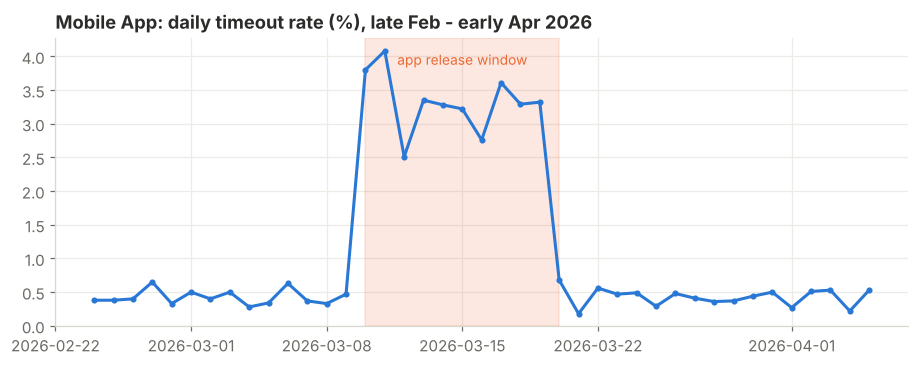

In [8]:
d = o('q15_daily_app_timeouts'); d['txn_date'] = pd.to_datetime(d.txn_date)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(d.txn_date, d.timeout_pct, color=an.PRIMARY, marker='o', ms=3)
ax.axvspan(pd.Timestamp('2026-03-10'), pd.Timestamp('2026-03-19 23:59'), color=an.HIGHLIGHT, alpha=0.15)
ax.text(pd.Timestamp('2026-03-15'), d.timeout_pct.max()*0.95, 'app release window', ha='center', color=an.HIGHLIGHT, fontsize=9)
ax.set_title("Mobile App: daily timeout rate (%), late Feb - early Apr 2026"); ax.set_ylim(0)
an.save(fig, "app_release_timeouts"); d.sort_values('timeout_pct', ascending=False).head(5)

App timeouts rose about **sevenfold for ten days from 10 March 2026**, then returned to normal: the pattern of a faulty release that was later fixed. The incident log records only a three-hour app outage on 13 March, so the release problem was never logged as an incident.

In [9]:
lat = o('q16_latency_by_channel_month')
lat.pivot(index='month', columns='channel', values='p95_ms').tail(6)

channel,ATM,Agent,Internet Banking,Mobile App,USSD,Wallet Link
month,,,,,,
2026-05-01,"4,818.00","5,317.00","3,255.00","3,876.00","9,358.00","8,757.00"
2026-06-01,"4,729.00","6,148.00","3,167.00","3,822.00","8,850.00","8,704.00"
2026-07-01,"4,696.00","5,286.00","3,205.00","3,875.00","8,750.00","8,565.00"
2026-08-01,"4,690.00","5,302.00","3,151.00","3,937.00","8,841.00","8,645.00"
2026-09-01,"4,727.00","5,414.00","3,294.00","3,876.00","8,916.00","8,412.00"
2026-10-01,"4,702.00","5,331.00","3,202.00","3,841.00","9,592.00","8,537.00"
